# AIDA Singaporean Malay Cohort — CellTypist Dose-Response Experiment

This notebook evaluates how the proportion of **Singaporean Malay donors** in the reference set
affects cell-type annotation accuracy (macro-F1) on a held-out Singaporean Malay query cohort,
using [CellTypist](https://www.celltypist.org/) trained on the AIDA atlas.

**Experimental design**
- Query: 20 randomly selected Singaporean Malay donors (fixed seed = 42)
- Reference: 60 donors total; proportion of same-ethnicity (Singaporean Malay) donors varies from 0 % to 100 %
- Metric: macro-averaged F1 across all cell types
- Repeats: 10 independent runs per proportion level

In [11]:
# ── Environment setup ──────────────────────────────────────────────────
# Install required packages (only needed on a fresh Colab runtime)
!pip install -q scanpy celltypist
!pip install -q 'pandas==2.2.3'

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Set working directory to the AIDA project folder
import os
os.chdir('/content/drive/MyDrive/aida-celltypist-bias')

# Imports
import scanpy as sc
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, classification_report
import celltypist
import scipy.sparse as sp

print('Environment ready.')

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
scanpy 1.12.4 requires pandas>=2.3, but you have pandas 2.2.3 which is incompatible.
anndata 0.13.4 requires pandas>=2.3, but you have pandas 2.2.3 which is incompatible.
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Environment ready.


## 1. Load AIDA Dataset

The dataset is loaded in **backed mode** so that only the required cells are pulled into memory.

In [ ]:
adata = sc.read_h5ad('/content/drive/MyDrive/aida-celltypist-bias/AIDA.h5ad', backed='r')
print(adata)

AnnData object with n_obs × n_vars = 1265624 × 35477 backed at '/content/drive/MyDrive/aida-celltypist-bias/AIDA.h5ad'
    obs: 'reference_genome', 'gene_annotation_version', 'alignment_software', 'intronic_reads_counted', 'library_id', 'assay_ontology_term_id', 'sequenced_fragment', 'cell_number_loaded', 'institute', 'is_primary_data', 'cell_type_ontology_term_id', 'author_cell_type', 'sample_id', 'sample_preservation_method', 'tissue_ontology_term_id', 'development_stage_ontology_term_id', 'sample_collection_method', 'donor_BMI_at_collection', 'tissue_type', 'suspension_derivation_process', 'suspension_enriched_cell_types', 'cell_viability_percentage', 'suspension_uuid', 'suspension_type', 'donor_id', 'self_reported_ethnicity_ontology_term_id', 'donor_living_at_sample_collection', 'disease_ontology_term_id', 'sex_ontology_term_id', 'nCount_RNA', 'nFeature_RNA', 'pMito', 'NODG', 'nUMI', 'Country', 'Annotation_Level1', 'Annotation_Level2', 'Annotation_Level3', 'Annotation_Level4', 'Smo

## 2. Define Query and Reference Donor Pools

- **Query donors** (n = 20): randomly drawn from the Singaporean Malay cohort (seed = 42, fixed for reproducibility).
- **Singaporean Malay reference candidates**: remaining Singaporean Malay donors not in the query set.
- **Other-ethnicity reference pool**: all donors from non-Singaporean Malay ethnic groups.

In [ ]:
n_ref_total = 60  # defined here so Cell 5 can use it
# ── Donor partitioning (seed fixed for reproducibility) ─────────────────
singaporean_malay_donors = adata.obs[
    adata.obs['self_reported_ethnicity'] == 'Singaporean Malay'
]['donor_id'].unique()

np.random.seed(42)
query_donors = np.random.choice(singaporean_malay_donors, size=20, replace=False)
ref_candidate_donors = singaporean_malay_donors[~np.isin(singaporean_malay_donors, query_donors)]

# All non-Singaporean Malay ethnic groups as the alternative reference pool
all_other_donors = adata.obs[
    adata.obs['self_reported_ethnicity'].isin([
        'Singaporean Chinese',
        'Japanese',
        'Korean',
        'Thai',
        'Indian',
        'Singaporean Indian'
    ])
]['donor_id'].unique()

print(f'Query donors          : {len(query_donors)}')
print(f'Singaporean Malay ref candidates: {len(ref_candidate_donors)}')
print(f'Other-ethnicity pool   : {len(all_other_donors)}')

# Auto-compute feasible proportions based on available ref candidates
_n_avail = len(ref_candidate_donors)
proportions = [p for p in [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
               if int(n_ref_total * p) <= _n_avail]
print(f'Ref candidates available: {_n_avail}')
print(f'Feasible proportions    : {proportions}')

Query donors          : 20
Singaporean Malay ref candidates: 41
Other-ethnicity pool   : 558
Ref candidates available: 41
Feasible proportions    : [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6]


## 3. CellTypist Training and Annotation Function

Each call assembles a reference of `n_ref_total` donors, trains a CellTypist model,
annotates the query, and returns the macro-F1 score.

In [ ]:
def run_celltypist(adata, query_donors, other_donors, ref_candidate_donors,
                   singaporean_malay_proportion, n_ref_total=60):
    """Train CellTypist on a mixed reference and annotate Singaporean Malay query donors.

    Parameters
    ----------
    singaporean_malay_proportion : float
        Fraction of the reference composed of Singaporean Malay donors (0.0 – 1.0).
    n_ref_total : int
        Total number of reference donors.
    """
    n_singaporean_malay = int(n_ref_total * singaporean_malay_proportion)
    n_others   = n_ref_total - n_singaporean_malay

    singaporean_malay_ref = (
        np.random.choice(ref_candidate_donors, size=n_singaporean_malay, replace=False)
        if n_singaporean_malay > 0 else []
    )
    other_ref      = np.random.choice(other_donors, size=n_others, replace=False)
    all_ref_donors = list(singaporean_malay_ref) + list(other_ref)

    print(f'  Building reference ({len(all_ref_donors)} donors)...')
    ref_adata = adata[adata.obs['donor_id'].isin(all_ref_donors)].to_memory()
    print(f'  Reference loaded   : {ref_adata.n_obs:,} cells')

    sc.pp.highly_variable_genes(ref_adata, n_top_genes=2000)
    ref_adata = ref_adata[:, ref_adata.var['highly_variable']]

    print('  Training CellTypist model...')
    model = celltypist.train(ref_adata, labels='cell_type', n_jobs=-1,
                            with_mean=False, check_expression=False)
    print('  Model trained.')

    query = adata[adata.obs['donor_id'].isin(query_donors)].to_memory()
    query = query[:, ref_adata.var_names].copy()
    if sp.issparse(query.X):
        query.X = query.X.toarray()

    predictions = celltypist.annotate(query, model=model)
    f1 = f1_score(query.obs['cell_type'],
                  predictions.predicted_labels['predicted_labels'],
                  average='macro')
    print(f'  Macro-F1: {f1:.4f}')
    return f1, predictions, query

print('Function ready.')

Function ready.


## 4. Run Full Dose-Response Experiment

> **⚠ WARNING — do NOT re-run Cell 4a.**  
> Results are already saved to `results_full_curve_singaporean_malay.csv` and `all_reports_singaporean_malay.json`.
> Re-running will overwrite the saved data.  
> Use **Cell 4b** below to append additional rounds instead.

In [ ]:
# ── Cell 4a — INITIAL RUN (protected) ──────────────────────────────────

raise Exception("Do NOT run this cell — results are already saved.")

import json
from sklearn.metrics import classification_report

SAVE_DIR = '/content/drive/MyDrive/aida-celltypist-bias/outputs/singaporean_malay'
os.makedirs(SAVE_DIR, exist_ok=True)
# proportions defined dynamically in Cell 5
n_repeats   = 8
all_results, all_reports = [], []

for i in range(n_repeats):
    print(f'\n=== Round {i + 1} ===')
    for prop in proportions:
        print(f'  Running {prop * 100:.0f}% Singaporean Malay...')
        f1, predictions, query = run_celltypist(
            adata, query_donors, all_other_donors,
            ref_candidate_donors, singaporean_malay_proportion=prop, n_ref_total=60
        )
        true_labels = query.obs['cell_type']
        pred_labels = predictions.predicted_labels['predicted_labels']
        report = classification_report(true_labels, pred_labels, output_dict=True)

        all_results.append({'proportion': prop, 'repeat': i, 'f1': f1})
        all_reports.append({'proportion': prop, 'repeat': i, 'report': report})

        # Save incrementally to Google Drive after every run
        pd.DataFrame(all_results).to_csv(
            f'{SAVE_DIR}/results_full_curve_singaporean_malay.csv', index=False)
        with open(f'{SAVE_DIR}/all_reports_singaporean_malay.json', 'w') as fh:
            json.dump(all_reports, fh)

df_results = pd.DataFrame(all_results)
print('\nMean macro-F1 by proportion:')
print(df_results.groupby('proportion')['f1'].mean())


=== Round 1 ===
  Running 0% Singaporean Malay...
  Building reference (60 donors)...
  Reference loaded   : 121,145 cells
  Training CellTypist model...
  Model trained.


  Macro-F1: 0.7835
  Running 10% Singaporean Malay...
  Building reference (60 donors)...
  Reference loaded   : 119,414 cells
  Training CellTypist model...
  Model trained.


  Macro-F1: 0.7881
  Running 20% Singaporean Malay...
  Building reference (60 donors)...
  Reference loaded   : 110,916 cells
  Training CellTypist model...
  Model trained.


  Macro-F1: 0.8251
  Running 30% Singaporean Malay...
  Building reference (60 donors)...
  Reference loaded   : 108,917 cells
  Training CellTypist model...
  Model trained.


  Macro-F1: 0.8284
  Running 40% Singaporean Malay...
  Building reference (60 donors)...
  Reference loaded   : 109,282 cells
  Training CellTypist model...
  Model trained.


  Macro-F1: 0.8263
  Running 50% Singaporean Malay...
  Building reference (60 donors)...
  Reference loaded   : 111,750 cells
  Training CellTypist model...
  Model trained.


... (47 outputs left out)

  Macro-F1: 0.8294
  Running 40% Singaporean Malay...
  Building reference (60 donors)...
  Reference loaded   : 117,035 cells
  Training CellTypist model...
  Model trained.


  Macro-F1: 0.8254
  Running 50% Singaporean Malay...
  Building reference (60 donors)...
  Reference loaded   : 113,986 cells
  Training CellTypist model...
  Model trained.


  Macro-F1: 0.8182
  Running 60% Singaporean Malay...
  Building reference (60 donors)...
  Reference loaded   : 111,852 cells
  Training CellTypist model...
  Model trained.


  Macro-F1: 0.8353

Mean macro-F1 by proportion:
proportion
0.0    0.800540
0.1    0.802910
0.2    0.812682
0.3    0.814441
0.4    0.822349
0.5    0.822330
0.6    0.821810
Name: f1, dtype: float64


## 4b. Resume / Append Additional Rounds

Adjust `n_extra_rounds` and run this cell to extend the experiment without overwriting existing results.

In [ ]:
import json

SAVE_DIR = '/content/drive/MyDrive/aida-celltypist-bias/outputs/singaporean_malay'

# Load existing results
with open(f'{SAVE_DIR}/all_reports_singaporean_malay.json', 'r') as fh:
    all_reports = json.load(fh)
all_results = pd.read_csv(f'{SAVE_DIR}/results_full_curve_singaporean_malay.csv').to_dict('records')

next_round = int(pd.read_csv(f'{SAVE_DIR}/results_full_curve_singaporean_malay.csv')['repeat'].max()) + 1
print(f'Completed rounds: {next_round}  |  Resuming from round {next_round + 1}')

# proportions defined dynamically in Cell 5
n_extra_rounds = 8  # ← set the number of additional rounds to run

for i in range(next_round, next_round + n_extra_rounds):
    print(f'\n=== Round {i + 1} ===')
    for prop in proportions:
        print(f'  Running {prop * 100:.0f}% Singaporean Malay...')
        f1, predictions, query = run_celltypist(
            adata, query_donors, all_other_donors,
            ref_candidate_donors, singaporean_malay_proportion=prop, n_ref_total=60
        )
        true_labels = query.obs['cell_type']
        pred_labels = predictions.predicted_labels['predicted_labels']
        report = classification_report(true_labels, pred_labels, output_dict=True)

        all_results.append({'proportion': prop, 'repeat': i, 'f1': f1})
        all_reports.append({'proportion': prop, 'repeat': i, 'report': report})

        pd.DataFrame(all_results).to_csv(
            f'{SAVE_DIR}/results_full_curve_singaporean_malay.csv', index=False)
        with open(f'{SAVE_DIR}/all_reports_singaporean_malay.json', 'w') as fh:
            json.dump(all_reports, fh)

print('Done.')

Completed rounds: 8  |  Resuming from round 9
Done.


## 5. Overall Dose-Response Results

Load the saved CSV and print mean macro-F1 for each proportion level.

In [2]:
SAVE_DIR = '/content/drive/MyDrive/aida-celltypist-bias/outputs/singaporean_malay'

df_results = pd.read_csv(f'{SAVE_DIR}/results_full_curve_singaporean_malay.csv')
print('Mean macro-F1 by Singaporean Malay proportion in reference:')
print(df_results.groupby('proportion')['f1'].mean().round(4))

Mean macro-F1 by Singaporean Malay proportion in reference:
proportion
0.0    0.8005
0.1    0.8029
0.2    0.8127
0.3    0.8144
0.4    0.8223
0.5    0.8223
0.6    0.8218
Name: f1, dtype: float64


## 6. Dose-Response Plot (Overall)

Macro-F1 (mean ± SD across repeats) as a function of Singaporean Malay donor proportion in the reference.

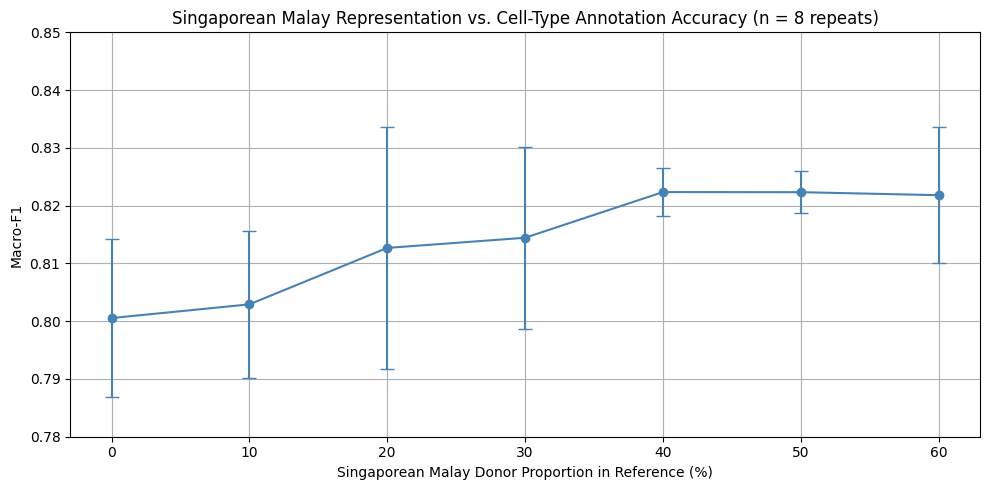

In [3]:
import matplotlib.pyplot as plt

SAVE_DIR = '/content/drive/MyDrive/aida-celltypist-bias/outputs/singaporean_malay'
df_results = pd.read_csv(f'{SAVE_DIR}/results_full_curve_singaporean_malay.csv')

means = df_results.groupby('proportion')['f1'].mean()
stds  = df_results.groupby('proportion')['f1'].std()
n     = int(df_results['repeat'].max()) + 1

fig, ax = plt.subplots(figsize=(10, 5))
ax.errorbar([p * 100 for p in means.index], means.values,
            yerr=stds.values, fmt='o-', capsize=5, color='steelblue')
ax.set_xlabel('Singaporean Malay Donor Proportion in Reference (%)')
ax.set_ylabel('Macro-F1')
ax.set_title(f'Singaporean Malay Representation vs. Cell-Type Annotation Accuracy (n = {n} repeats)')
ax.set_ylim(0.78, 0.85)
ax.grid(True)
fig.tight_layout()
fig.savefig(f'{SAVE_DIR}/dose_response_final_singaporean_malay.png', dpi=150)
plt.show()

## 7. Per-Cell-Type Analysis — Rare Cell Types

Cell types with mean query support < 200 cells are treated as rare.
F1 curves are plotted across all proportion levels for each rare type.

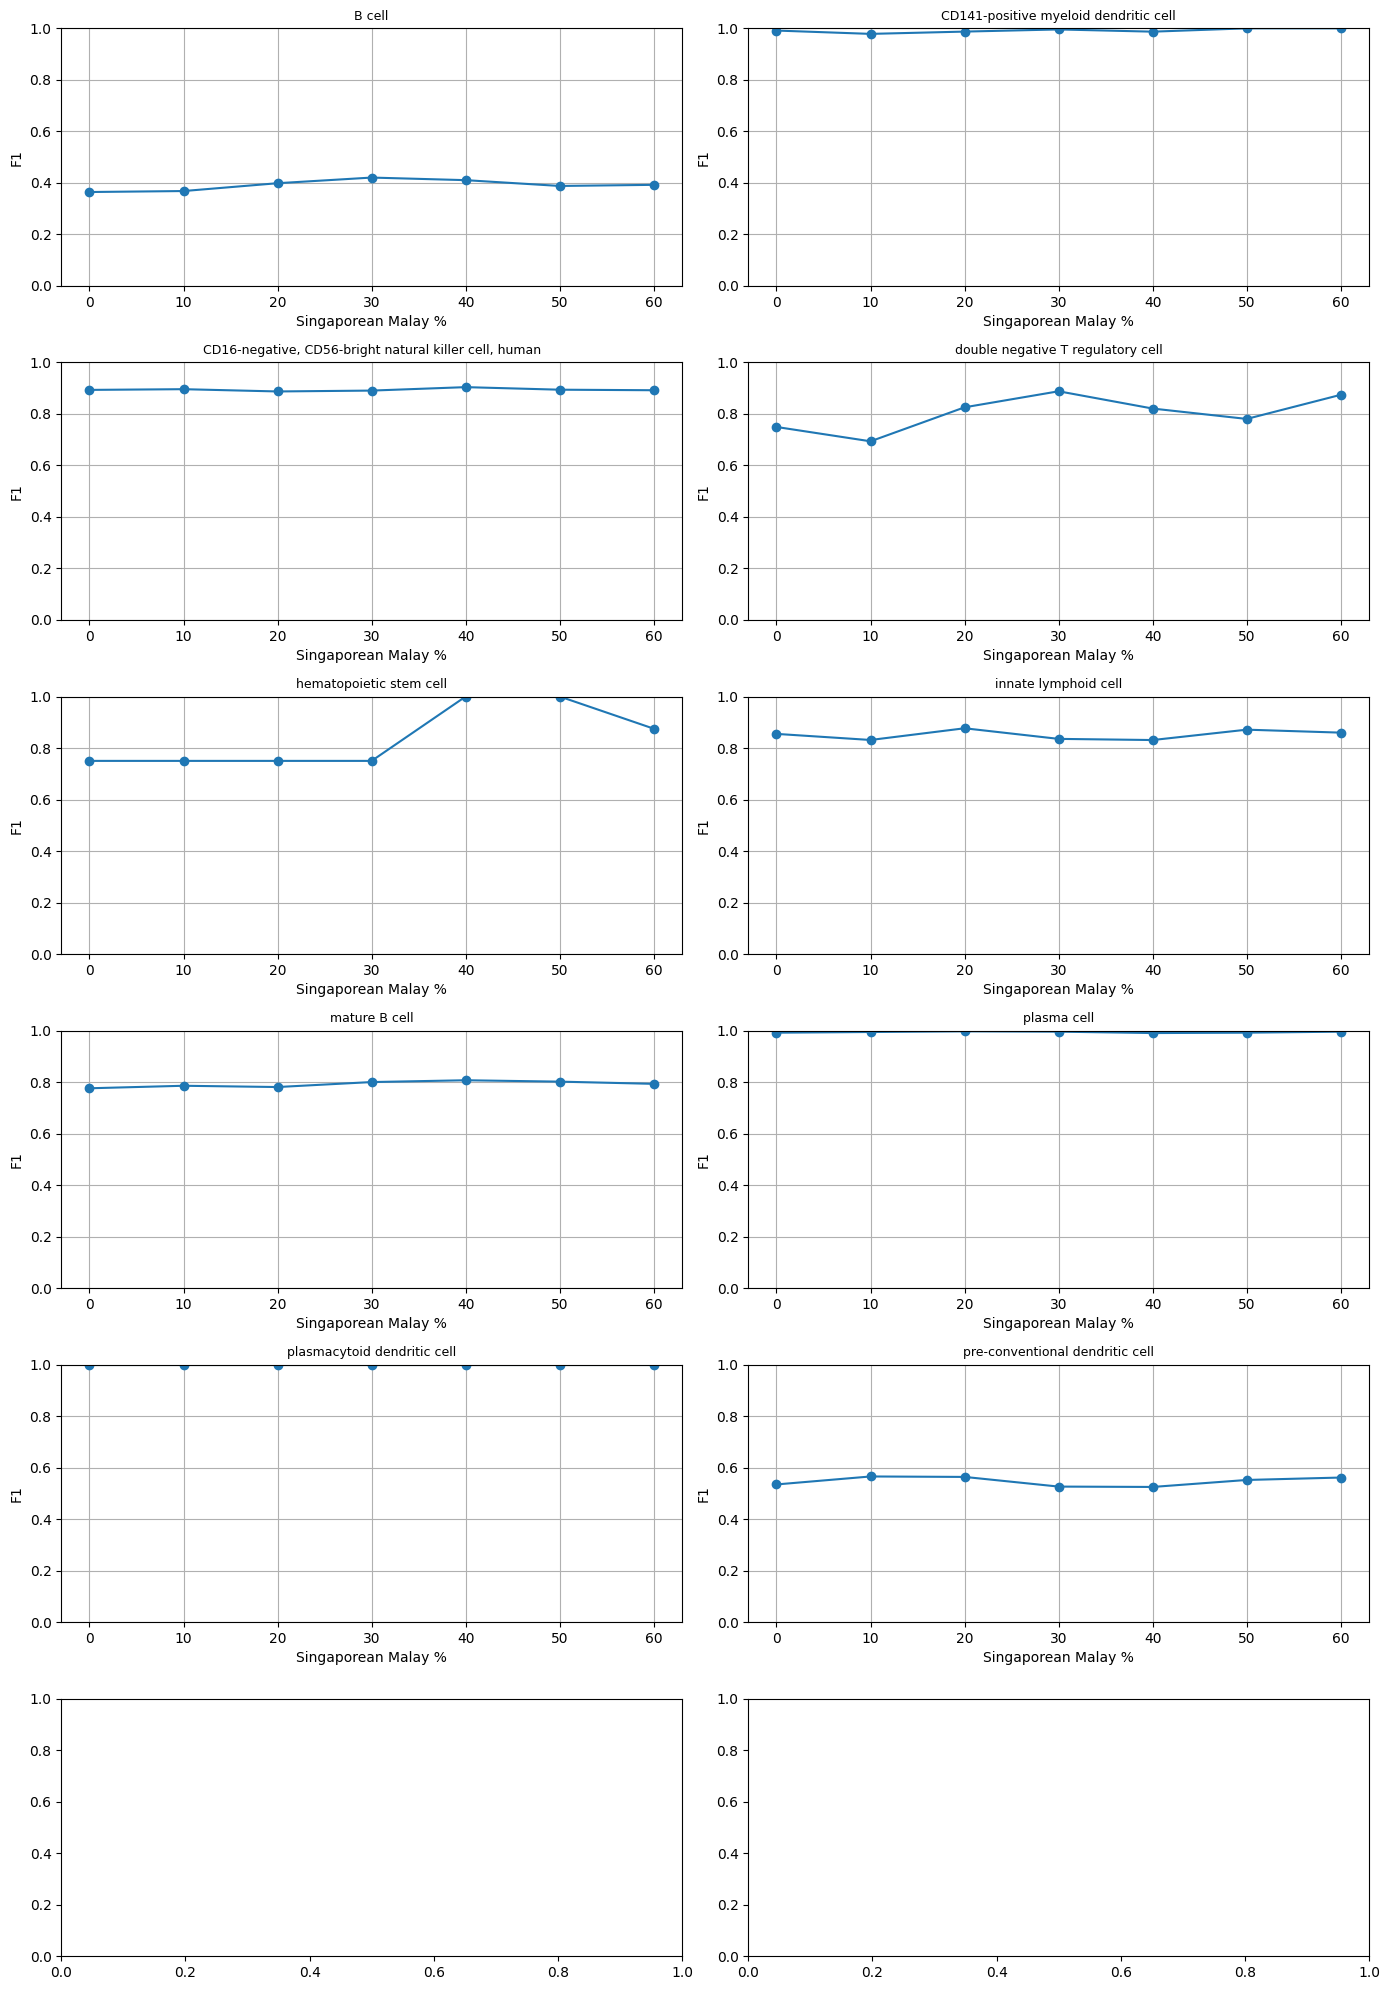

In [4]:
import json

SAVE_DIR = '/content/drive/MyDrive/aida-celltypist-bias/outputs/singaporean_malay'

with open(f'{SAVE_DIR}/all_reports_singaporean_malay.json', 'r') as fh:
    all_reports = json.load(fh)

# Build per-cell-type F1 table
cell_type_results = []
for entry in all_reports:
    for cell_type, metrics in entry['report'].items():
        if cell_type in ('accuracy', 'macro avg', 'weighted avg'):
            continue
        if isinstance(metrics, dict):
            cell_type_results.append({
                'proportion': entry['proportion'],
                'cell_type' : cell_type,
                'f1'        : metrics['f1-score'],
                'support'   : metrics['support'],
            })

df_cell = pd.DataFrame(cell_type_results)

# Identify rare cell types (mean support < 200)
rare_cells = df_cell.groupby('cell_type')['support'].mean()
rare_cells = rare_cells[rare_cells < 200].index

mean_by_cell = (
    df_cell[df_cell['cell_type'].isin(rare_cells)]
    .groupby(['cell_type', 'proportion'])['f1'].mean().unstack()
)

fig, axes = plt.subplots(len(rare_cells) // 2 + 1, 2, figsize=(14, 20))
axes = axes.flatten()
for idx, ct in enumerate(rare_cells):
    if ct in mean_by_cell.index:
        axes[idx].plot([p * 100 for p in mean_by_cell.columns],
                       mean_by_cell.loc[ct].values, 'o-')
        axes[idx].set_title(ct, fontsize=9)
        axes[idx].set_xlabel('Singaporean Malay %')
        axes[idx].set_ylabel('F1')
        axes[idx].set_ylim(0, 1)
        axes[idx].grid(True)
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/rare_celltypes_curve_singaporean_malay.png', dpi=150)
plt.show()

## 8. Mean F1 by Cell Type (Full Table)

In [5]:
import json

SAVE_DIR = '/content/drive/MyDrive/aida-celltypist-bias/outputs/singaporean_malay'

with open(f'{SAVE_DIR}/all_reports_singaporean_malay.json', 'r') as fh:
    all_reports = json.load(fh)

cell_type_results = []
for entry in all_reports:
    for cell_type, metrics in entry['report'].items():
        if cell_type in ('accuracy', 'macro avg', 'weighted avg'):
            continue
        if isinstance(metrics, dict):
            cell_type_results.append({
                'proportion': entry['proportion'],
                'cell_type' : cell_type,
                'f1'        : metrics['f1-score'],
                'support'   : metrics['support'],
            })

df_cell      = pd.DataFrame(cell_type_results)
mean_by_cell = df_cell.groupby(['cell_type', 'proportion'])['f1'].mean().unstack()

print('Mean F1 by cell type across all proportion levels:')
print(mean_by_cell.round(3))

Mean F1 by cell type across all proportion levels:
proportion                                            0.0    0.1    0.2  \
cell_type                                                                 
B cell                                              0.364  0.368  0.399   
CD14-low, CD16-positive monocyte                    0.961  0.960  0.963   
CD14-positive monocyte                              0.971  0.970  0.971   
CD141-positive myeloid dendritic cell               0.991  0.978  0.987   
CD16-negative, CD56-bright natural killer cell,...  0.893  0.896  0.887   
CD16-positive, CD56-dim natural killer cell, human  0.979  0.980  0.981   
CD1c-positive myeloid dendritic cell                0.871  0.871  0.870   
CD4-positive, alpha-beta T cell                     0.281  0.286  0.312   
CD4-positive, alpha-beta cytotoxic T cell           0.764  0.769  0.774   
CD8-positive, alpha-beta T cell                     0.628  0.632  0.638   
CD8-positive, alpha-beta cytotoxic T cell        

## 9. Identify Cell Types Most Sensitive to Singaporean Malay Proportion

Cell types with |F1(60%) − F1(0%)| > 0.03 are selected for detailed analysis.

In [6]:
# F1 difference: 100% Singaporean Malay reference vs. 0% Singaporean Malay reference
diff = mean_by_cell[0.6] - mean_by_cell[0.0]
diff = diff.sort_values()

print('F1 difference (100% Singaporean Malay − 0% Singaporean Malay):')
print(diff.round(3))

F1 difference (100% Singaporean Malay − 0% Singaporean Malay):
cell_type
myeloid cell                                            -0.011
CD1c-positive myeloid dendritic cell                    -0.005
platelet                                                -0.003
CD16-negative, CD56-bright natural killer cell, human   -0.001
CD14-positive monocyte                                  -0.000
plasmacytoid dendritic cell                              0.000
CD14-low, CD16-positive monocyte                         0.002
CD16-positive, CD56-dim natural killer cell, human       0.003
naive B cell                                             0.004
plasma cell                                              0.004
innate lymphoid cell                                     0.005
mucosal-associated invariant T cell                      0.007
effector memory CD4-positive, alpha-beta T cell          0.007
memory B cell                                            0.007
CD141-positive myeloid dendritic cell        

## 10. Dose-Response Curves for Sensitive Cell Types

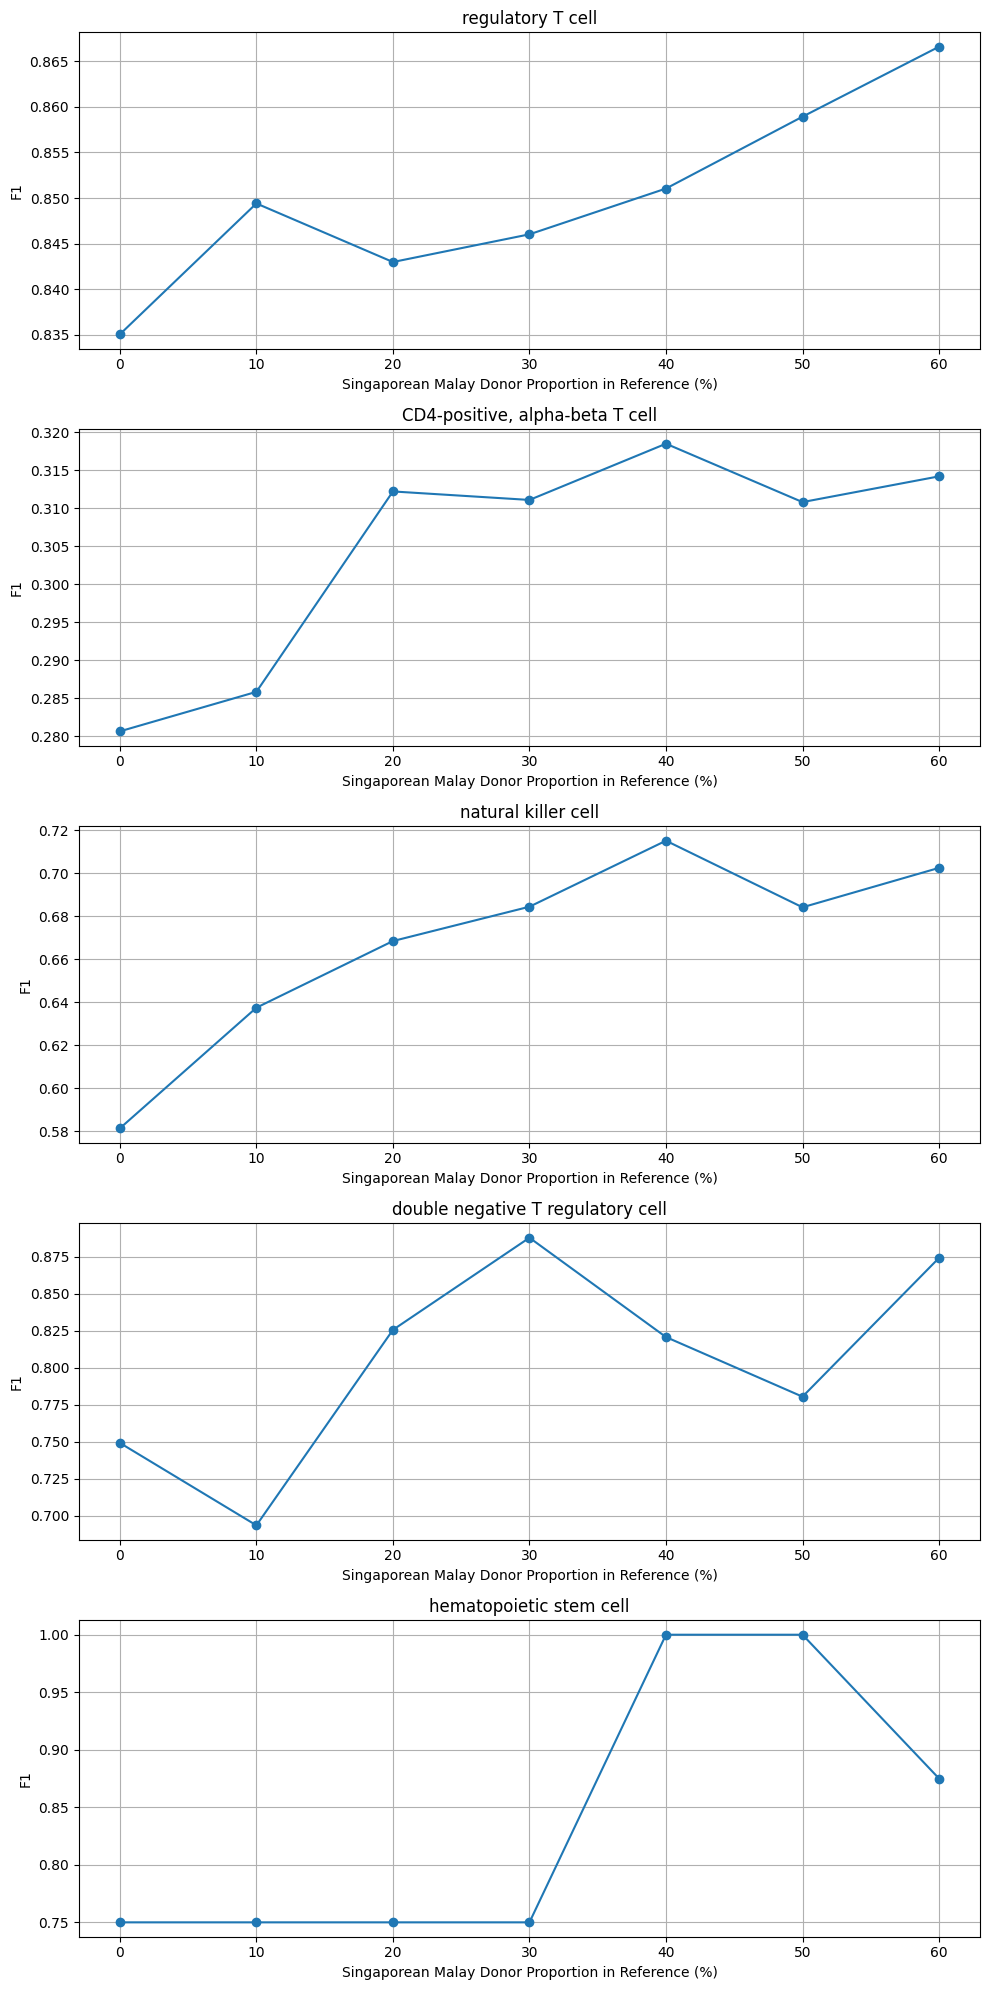

In [7]:
import matplotlib.pyplot as plt

SAVE_DIR = '/content/drive/MyDrive/aida-celltypist-bias/outputs/singaporean_malay'

# Cell types with |ΔF1| > 0.03
important_cells = diff[abs(diff) > 0.03].index.tolist()

fig, axes = plt.subplots(len(important_cells), 1,
                         figsize=(10, 4 * len(important_cells)))

for idx, ct in enumerate(important_cells):
    axes[idx].plot([p * 100 for p in mean_by_cell.columns],
                   mean_by_cell.loc[ct].values, 'o-')
    axes[idx].set_title(ct)
    axes[idx].set_xlabel('Singaporean Malay Donor Proportion in Reference (%)')
    axes[idx].set_ylabel('F1')
    axes[idx].grid(True)

plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/important_celltypes_curve_singaporean_malay.png', dpi=150)
plt.show()

## 11. Export Sensitive Cell-Type Data

In [8]:
SAVE_DIR = '/content/drive/MyDrive/aida-celltypist-bias/outputs/singaporean_malay'

important_cells = diff[abs(diff) > 0.03].index.tolist()
df_important    = df_cell[df_cell['cell_type'].isin(important_cells)].copy()

df_important.to_csv(f'{SAVE_DIR}/important_celltypes_singaporean_malay.csv', index=False)
print('Saved: important_celltypes_singaporean_malay.csv')
print(f'Cell types included: {important_cells}')
print(df_important.groupby(['cell_type', 'proportion'])['f1'].mean().round(3))

Saved: important_celltypes_singaporean_malay.csv
Cell types included: ['regulatory T cell', 'CD4-positive, alpha-beta T cell', 'natural killer cell', 'double negative T regulatory cell', 'hematopoietic stem cell']
cell_type                          proportion
CD4-positive, alpha-beta T cell    0.0           0.281
                                   0.1           0.286
                                   0.2           0.312
                                   0.3           0.311
                                   0.4           0.318
                                   0.5           0.311
                                   0.6           0.314
double negative T regulatory cell  0.0           0.749
                                   0.1           0.694
                                   0.2           0.826
                                   0.3           0.888
                                   0.4           0.821
                                   0.5           0.781
                         

## 12. Heatmap — F1 by Cell Type and Singaporean Malay Proportion

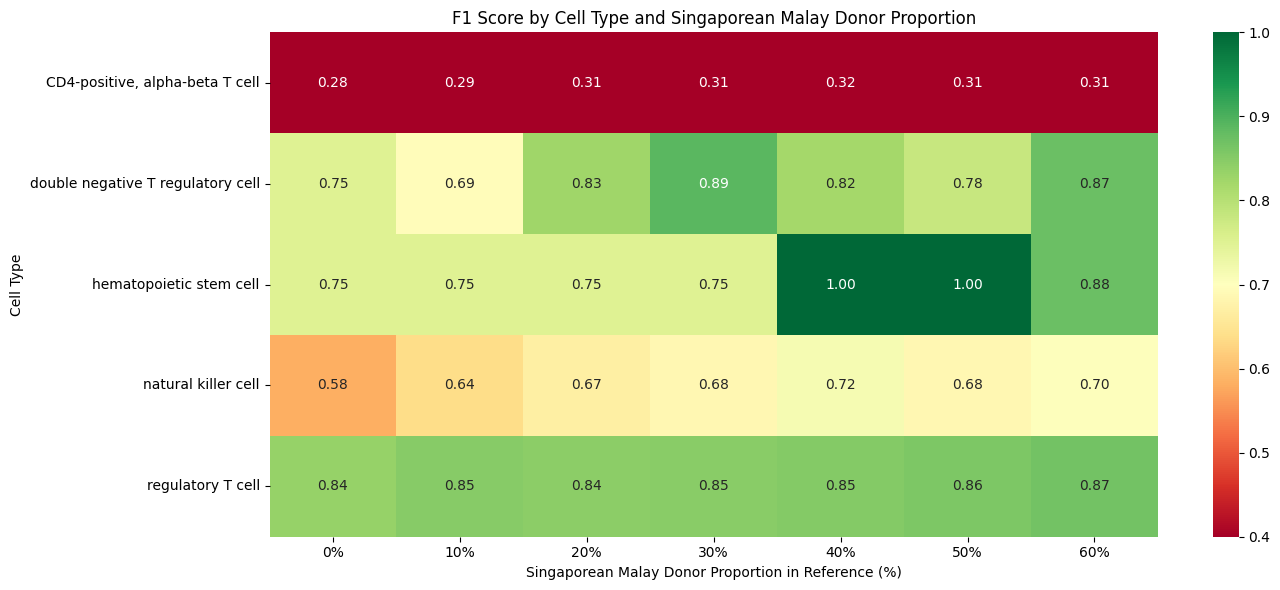

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

SAVE_DIR = '/content/drive/MyDrive/aida-celltypist-bias/outputs/singaporean_malay'

pivot = df_important.groupby(['cell_type', 'proportion'])['f1'].mean().unstack()

fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(pivot, annot=True, fmt='.2f', cmap='RdYlGn',
            xticklabels=[f'{int(p * 100)}%' for p in pivot.columns],
            vmin=0.4, vmax=1.0, ax=ax)
ax.set_xlabel('Singaporean Malay Donor Proportion in Reference (%)')
ax.set_ylabel('Cell Type')
ax.set_title('F1 Score by Cell Type and Singaporean Malay Donor Proportion')
fig.tight_layout()
fig.savefig(f'{SAVE_DIR}/heatmap_important_celltypes_singaporean_malay.png', dpi=150)
plt.show()

## 13. Line Chart — F1 by Cell Type and Singaporean Malay Proportion

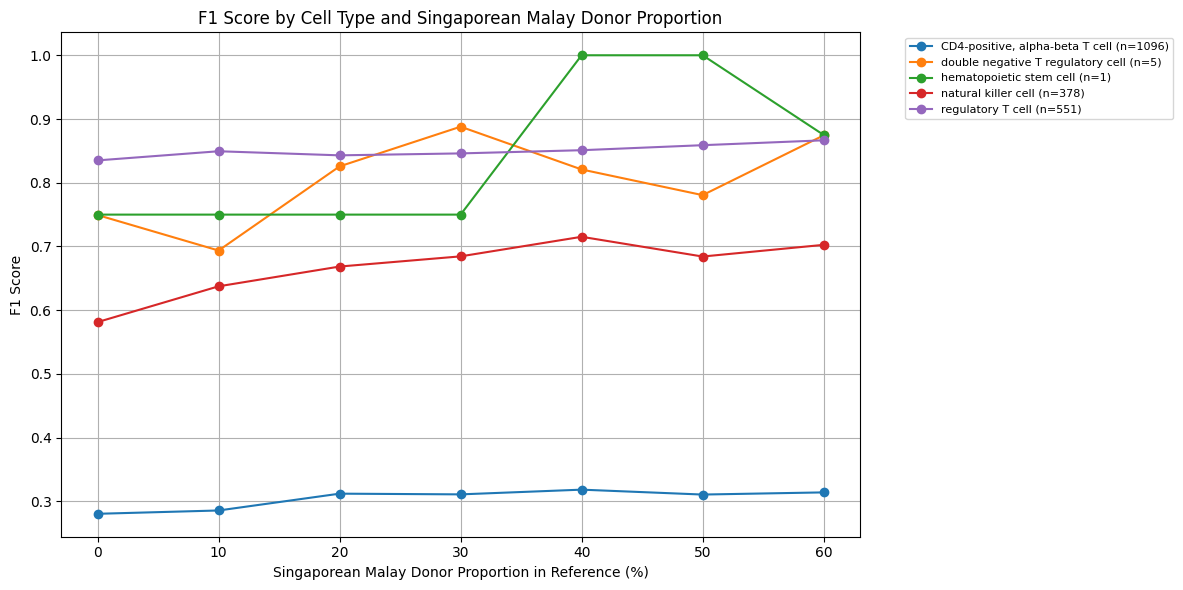

In [10]:
import matplotlib.pyplot as plt

SAVE_DIR = '/content/drive/MyDrive/aida-celltypist-bias/outputs/singaporean_malay'

support_by_cell = df_important.groupby('cell_type')['support'].mean().round(0).astype(int)
pivot           = df_important.groupby(['cell_type', 'proportion'])['f1'].mean().unstack()

fig, ax = plt.subplots(figsize=(12, 6))
for ct in pivot.index:
    ax.plot([p * 100 for p in pivot.columns],
            pivot.loc[ct].values,
            'o-', label=f'{ct} (n={support_by_cell[ct]})', linewidth=1.5)

ax.set_xlabel('Singaporean Malay Donor Proportion in Reference (%)')
ax.set_ylabel('F1 Score')
ax.set_title('F1 Score by Cell Type and Singaporean Malay Donor Proportion')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
ax.grid(True)
fig.tight_layout()
fig.savefig(f'{SAVE_DIR}/linechart_important_celltypes_singaporean_malay.png', dpi=150)
plt.show()